# 05 — Final Evaluation (cu best params din Optuna)

**Pași:**
1. Citește `best_params.json` din Tier 1 și Tier 5 (notebook 03 + 04)
2. Strategie: Tier 1 folosește params Tier 1; Tier 2-5 folosesc params Tier 5
3. Re-train cu best params (mai multe epoci, fără pruning)
4. Evaluează pe TEST set + per-source breakdown (HAM/BCN/MSK)
5. Salvează `test_results.json`, `test_predictions.csv`, plots

**Compute estimat:** ~1h × 5 tier-uri = **~5h total**.

**Output:** `experiments/efficientnetv2b0/tier{1-5}/D_final/`


## 1. Setup


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
print('Drive mounted')

Mounted at /content/drive
Drive mounted


In [ ]:
import os
import json
import time
import random
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import backend as K
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    precision_recall_fscore_support,
)

# ─── REPRODUCIBILITY ───
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print(f'TF: {tf.__version__}')
print(f'GPU: {tf.config.list_physical_devices("GPU")}')
print(f'Seed: {SEED}')

TF: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Seed: 42


In [ ]:
# ─── PATHS ───
DRIVE_BASE = Path('/content/drive/MyDrive/Thesis')
PIPELINE_DIR = DRIVE_BASE / 'pipeline_outputs'

TFRECORDS_DIR = PIPELINE_DIR / 'step4_tfrecords'   # val/, test/, tier5/
STEP2_DIR = PIPELINE_DIR / 'step2'                 # tier{N}_train.csv
EXPERIMENTS_DIR = DRIVE_BASE / 'experiments' / 'efficientnetv2b0'
EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)

# ─── HYPERPARAMETERS ───
IMG_SIZE = 224
NUM_CLASSES = 7
BATCH_SIZE = 32
DENSE1_UNITS = 1024
DENSE2_UNITS = 256
DROPOUT_RATE = 0.3
ROTATION_MAX_DEG = 20
ZOOM_RANGE = 0.1

PAPER_TRAINABLE_PARAMS = 7_437_207

# ─── LABELS ───
IDX_TO_LABEL = {0: 'akiec', 1: 'bcc', 2: 'bkl', 3: 'df', 4: 'mel', 5: 'nv', 6: 'vasc'}
CLASS_NAMES = [IDX_TO_LABEL[i] for i in range(NUM_CLASSES)]

print(f'TFRecords:   {TFRECORDS_DIR.exists()} {TFRECORDS_DIR}')
print(f'Step2:       {STEP2_DIR.exists()} {STEP2_DIR}')
print(f'Experiments: {EXPERIMENTS_DIR}')

for split in ['val', 'test', 'tier5']:
    d = TFRECORDS_DIR / split
    if d.exists():
        shards = sorted(d.glob('*.tfrecord'))
        print(f'  {split}: {len(shards)} shards')
    else:
        print(f'  [WARNING] {split}/ missing!')

TFRecords:   True /content/drive/MyDrive/Thesis/pipeline_outputs/step4_tfrecords
Step2:       True /content/drive/MyDrive/Thesis/pipeline_outputs/step2
Experiments: /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0
  val: 3 shards
  test: 3 shards
  tier5: 21 shards


## 2. Data pipeline


In [ ]:
FEATURE_DESC = {
    'image_id':    tf.io.FixedLenFeature([], tf.string),
    'label':       tf.io.FixedLenFeature([], tf.int64),
    'lesion_id':   tf.io.FixedLenFeature([], tf.string),
    'source':      tf.io.FixedLenFeature([], tf.string),
    'image_bytes': tf.io.FixedLenFeature([], tf.string),
}


def parse_example(example_proto):
    return tf.io.parse_single_example(example_proto, FEATURE_DESC)


def decode_image(parsed):
    img = tf.io.decode_jpeg(parsed['image_bytes'], channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32) / 255.0
    return img, parsed['label'], parsed['lesion_id']


def decode_with_source(parsed):
    img = tf.io.decode_jpeg(parsed['image_bytes'], channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32) / 255.0
    return img, parsed['label'], parsed['source']


def get_split_files(split_name):
    pattern = str(TFRECORDS_DIR / split_name / '*.tfrecord')
    files = sorted(tf.io.gfile.glob(pattern))
    if not files:
        raise FileNotFoundError(f'No TFRecords found for split: {split_name}')
    return files


TRAIN_FILES = get_split_files('tier5')
VAL_FILES = get_split_files('val')
TEST_FILES = get_split_files('test')

print(f'Train pool: {len(TRAIN_FILES)} shards')
print(f'Val:        {len(VAL_FILES)} shards')
print(f'Test:       {len(TEST_FILES)} shards')

Train pool: 21 shards
Val:        3 shards
Test:       3 shards


In [ ]:
def get_tier_lesion_ids(tier):
    if tier == 5:
        return None
    csv_path = STEP2_DIR / f'tier{tier}_train.csv'
    df = pd.read_csv(csv_path)
    return set(df['lesion_id'].astype(str).tolist())


def make_lesion_filter(allowed_ids):
    keys = tf.constant(sorted(list(allowed_ids)), dtype=tf.string)
    values = tf.ones(len(allowed_ids), dtype=tf.int32)
    return tf.lookup.StaticHashTable(
        tf.lookup.KeyValueTensorInitializer(keys, values),
        default_value=0,
    )


for t in [1, 2, 3, 4, 5]:
    ids = get_tier_lesion_ids(t)
    if ids is None:
        print(f'Tier {t}: no filter (full tier5)')
    else:
        print(f'Tier {t}: {len(ids):,} lesion_ids')

Tier 1: 5,987 lesion_ids
Tier 2: 7,276 lesion_ids
Tier 3: 8,565 lesion_ids
Tier 4: 9,855 lesion_ids
Tier 5: no filter (full tier5)


In [ ]:
# ─── Augmentation: flip + rotation ±20° + zoom ±10% ───
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal_and_vertical', seed=SEED),
    tf.keras.layers.RandomRotation(
        factor=ROTATION_MAX_DEG / 360.0,
        fill_mode='reflect', seed=SEED,
    ),
    tf.keras.layers.RandomZoom(
        height_factor=(-ZOOM_RANGE, ZOOM_RANGE),
        width_factor=(-ZOOM_RANGE, ZOOM_RANGE),
        fill_mode='reflect', seed=SEED,
    ),
], name='paper_augmentation')


def preprocess_efficientnet(img_01):
    """Input [0,1] → [-1,1]."""
    return (img_01 * 255.0) / 127.5 - 1.0


print('Augmentation + preprocessing definite')

Augmentation + preprocessing definite


In [ ]:
def build_train_ds(tier, rotation_deg=ROTATION_MAX_DEG, zoom=ZOOM_RANGE):
    """Train ds — repeat + filter pe lesion_id pentru tier1-4."""
    allowed_ids = get_tier_lesion_ids(tier)

    # Augmentation layer per call (allows different rotation/zoom in Optuna)
    aug = tf.keras.Sequential([
        tf.keras.layers.RandomFlip('horizontal_and_vertical', seed=SEED),
        tf.keras.layers.RandomRotation(
            factor=rotation_deg / 360.0,
            fill_mode='reflect', seed=SEED,
        ),
        tf.keras.layers.RandomZoom(
            height_factor=(-zoom, zoom),
            width_factor=(-zoom, zoom),
            fill_mode='reflect', seed=SEED,
        ),
    ])

    ds = tf.data.TFRecordDataset(TRAIN_FILES, num_parallel_reads=tf.data.AUTOTUNE)
    ds = ds.map(parse_example, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(decode_image, num_parallel_calls=tf.data.AUTOTUNE)

    if allowed_ids is not None:
        table = make_lesion_filter(allowed_ids)
        ds = ds.filter(lambda img, lbl, lid: tf.equal(table.lookup(lid), 1))

    ds = ds.map(lambda img, lbl, lid: (img, lbl), num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.repeat()
    ds = ds.shuffle(buffer_size=2000, seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(
        lambda img, lbl: (aug(img, training=True), lbl),
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    ds = ds.map(
        lambda img, lbl: (preprocess_efficientnet(img), lbl),
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    ds = ds.batch(BATCH_SIZE, drop_remainder=True)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds


def build_eval_ds(files, with_source=False):
    ds = tf.data.TFRecordDataset(files, num_parallel_reads=tf.data.AUTOTUNE)
    ds = ds.map(parse_example, num_parallel_calls=tf.data.AUTOTUNE)
    if with_source:
        ds = ds.map(decode_with_source, num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.map(
            lambda img, lbl, src: (preprocess_efficientnet(img), lbl, src),
            num_parallel_calls=tf.data.AUTOTUNE,
        )
    else:
        ds = ds.map(decode_image, num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.map(lambda img, lbl, lid: (img, lbl), num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.map(
            lambda img, lbl: (preprocess_efficientnet(img), lbl),
            num_parallel_calls=tf.data.AUTOTUNE,
        )
    ds = ds.batch(BATCH_SIZE, drop_remainder=False)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds


print('Dataset builders definite')

Dataset builders definite


In [ ]:
def count_tier_samples(tier):
    allowed_ids = get_tier_lesion_ids(tier)
    ds = tf.data.TFRecordDataset(TRAIN_FILES, num_parallel_reads=tf.data.AUTOTUNE)
    ds = ds.map(parse_example, num_parallel_calls=tf.data.AUTOTUNE)
    if allowed_ids is not None:
        table = make_lesion_filter(allowed_ids)
        ds = ds.filter(lambda x: tf.equal(table.lookup(x['lesion_id']), 1))
    counter = Counter()
    for ex in ds:
        counter[int(ex['label'].numpy())] += 1
    return dict(counter)


TIER_DISTRIBUTIONS = {}
print('Counting samples per tier (~1-2 min):')
for t in [1, 2, 3, 4, 5]:
    dist = count_tier_samples(t)
    TIER_DISTRIBUTIONS[t] = dist
    total = sum(dist.values())
    print(f'  Tier {t}: {total:>6,} samples')

val_count = sum(1 for _ in tf.data.TFRecordDataset(VAL_FILES))
test_count = sum(1 for _ in tf.data.TFRecordDataset(TEST_FILES))
print(f'\nVal:  {val_count:,}')
print(f'Test: {test_count:,}')

Counting samples per tier (~1-2 min):
  Tier 1:  8,042 samples
  Tier 2: 10,996 samples
  Tier 3: 14,061 samples
  Tier 4: 17,300 samples
  Tier 5: 20,299 samples

Val:  2,519
Test: 2,513


## 3. Focal loss + Model + Eval


In [ ]:
def compute_alpha_inverse_frequency(distribution, normalize=True):
    """sklearn 'balanced' alpha. Output: array de shape (num_classes,)."""
    counts = np.array([distribution[i] for i in range(NUM_CLASSES)], dtype=np.float32)
    total = counts.sum()
    alpha = total / (NUM_CLASSES * counts)
    if normalize:
        alpha = alpha / alpha.max()
    return alpha


def categorical_focal_loss(alpha, gamma=2.0):
    """Categorical focal loss cu alpha per clasa.

    FL(p_t) = -α_t · (1 - p_t)^γ · log(p_t)

    Folosim sparse labels (int) → one-hot intern.
    """
    alpha = tf.constant(alpha, dtype=tf.float32)

    def loss(y_true, y_pred):
        # y_true vine ca int64 (labels), y_pred ca probabilități softmax
        y_true_oh = tf.one_hot(tf.cast(y_true, tf.int32), depth=NUM_CLASSES)
        y_pred = tf.clip_by_value(y_pred, K.epsilon(), 1.0 - K.epsilon())
        ce = -y_true_oh * tf.math.log(y_pred)
        focal_weight = tf.pow(1.0 - y_pred, gamma)
        weighted_loss = alpha * focal_weight * ce
        return tf.reduce_mean(tf.reduce_sum(weighted_loss, axis=-1))

    return loss


# Sanity check pe Tier 5
alpha_t5 = compute_alpha_inverse_frequency(TIER_DISTRIBUTIONS[5])
print('Alpha for Tier 5 (normalized to max=1):')
for i, name in enumerate(CLASS_NAMES):
    print(f'  {name}: {alpha_t5[i]:.4f}')

Alpha for Tier 5 (normalized to max=1):
  akiec: 0.1544
  bcc: 0.0691
  bkl: 0.0865
  df: 1.0000
  mel: 0.0507
  nv: 0.0179
  vasc: 0.8804


In [ ]:
def build_efficientnetv2b0(
    dense1=DENSE1_UNITS, dense2=DENSE2_UNITS, dropout=DROPOUT_RATE,
    base_trainable=True, verbose=True,
):
    """Strict Nawaz Table 4 — Total 7,500,375 / Trainable 7,437,207 (with full unfreeze)."""
    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    base = tf.keras.applications.EfficientNetV2B0(
        include_top=False,
        weights='imagenet',
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
    )
    base.trainable = base_trainable

    # CRITICAL: training=False chiar și pentru bază unfrozen (BN folosește moving avg).
    x = base(inputs, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(dense1, activation='relu')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Dropout(dropout)(x)
    x = tf.keras.layers.Dense(dense2, activation='relu')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Dropout(dropout)(x)
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)

    model = tf.keras.Model(inputs, outputs, name='EfficientNetV2B0')
    model.base_model = base

    if verbose:
        total = model.count_params()
        trainable = sum(tf.size(w).numpy() for w in model.trainable_weights)
        print(f'  Total: {total:,} | Trainable: {trainable:,}')
    return model


def set_phase_1(model):
    """Phase 1: head only."""
    model.base_model.trainable = False
    trainable = sum(tf.size(w).numpy() for w in model.trainable_weights)
    print(f'[Phase 1] Trainable: {trainable:,}')


def set_phase_2(model):
    """Phase 2: full unfreeze (BN stays frozen via training=False)."""
    model.base_model.trainable = True
    trainable = sum(tf.size(w).numpy() for w in model.trainable_weights)
    print(f'[Phase 2] Trainable: {trainable:,}')


_test = build_efficientnetv2b0()
del _test
tf.keras.backend.clear_session()

24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
  Total: 7,500,375 | Trainable: 7,437,207


In [ ]:
def evaluate_model(model, ds, label='test'):
    print(f'Evaluating on {label}...')
    y_true, y_pred, y_proba = [], [], []
    for imgs, labels in ds:
        preds = model.predict(imgs, verbose=0)
        y_proba.extend(preds)
        y_pred.extend(np.argmax(preds, axis=1))
        y_true.extend(labels.numpy())

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_proba = np.array(y_proba)

    acc = float(np.mean(y_true == y_pred))
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='weighted', zero_division=0,
    )
    macro_f1 = precision_recall_fscore_support(
        y_true, y_pred, average='macro', zero_division=0,
    )[2]
    try:
        auc = float(roc_auc_score(y_true, y_proba, multi_class='ovr', average='weighted'))
    except Exception:
        auc = float('nan')

    cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    report = classification_report(
        y_true, y_pred, target_names=CLASS_NAMES, zero_division=0,
    )

    print(f'  Accuracy:    {acc*100:.2f}%')
    print(f'  Precision:   {prec:.4f}')
    print(f'  Recall:      {rec:.4f}')
    print(f'  Weighted F1: {f1:.4f}')
    print(f'  Macro F1:    {macro_f1:.4f}')
    print(f'  AUC (ovr):   {auc:.4f}')

    return {
        'accuracy': acc, 'precision': float(prec), 'recall': float(rec),
        'weighted_f1': float(f1), 'macro_f1': float(macro_f1), 'auc': auc,
        'confusion_matrix': cm.tolist(),
        'classification_report': report,
        'y_true': y_true.tolist(), 'y_pred': y_pred.tolist(),
        'y_proba': y_proba.tolist(),
    }

## 4. Load best params din Optuna


In [ ]:
best_params = {}
for tier in [1, 5]:
    bp_path = EXPERIMENTS_DIR / f'tier{tier}' / 'C_optuna' / 'best_params.json'
    if bp_path.exists():
        with open(bp_path) as f:
            best_params[tier] = json.load(f)
        print(f'Tier {tier}: val_acc = {best_params[tier]["best_value"]:.4f}')
        for k, v in best_params[tier]['best_params'].items():
            print(f'  {k}: {v}')
        print()
    else:
        print(f'⚠ Tier {tier} Optuna results NOT found at {bp_path}')
        print(f'  Run notebook {"03" if tier == 1 else "04"} first!')
        best_params[tier] = None


def get_params_for_tier(tier):
    """Strategie: Tier 1 → params Tier 1; Tier 2-5 → params Tier 5."""
    if tier == 1 and best_params.get(1):
        return best_params[1]['best_params']
    if best_params.get(5):
        return best_params[5]['best_params']
    raise ValueError(f'No best_params available for tier {tier}')


Tier 1: val_acc = 0.5657
  learning_rate: 0.00015258739809889343
  dropout: 0.45263205004106066
  dense1_units: 1024
  dense2_units: 256
  rotation_max: 30
  zoom_range: 0.03767864421590901
  focal_gamma: 2.171403216793168

Tier 5: val_acc = 0.6590
  learning_rate: 8.340431367949276e-05
  dropout: 0.443073037065547
  dense1_units: 2048
  dense2_units: 256
  rotation_max: 10
  zoom_range: 0.16401404987609786
  focal_gamma: 1.7713090263819145



## 5. Per-source evaluation helper


In [ ]:
def evaluate_per_source(model, test_files):
    """Evaluează test set și returnează metrici per-source (HAM/BCN/MSK)."""
    print('Collecting predictions cu source labels...')
    ds = build_eval_ds(test_files, with_source=True)

    all_y_true, all_y_pred, all_y_proba, all_sources = [], [], [], []

    for imgs, labels, sources in ds:
        preds = model.predict(imgs, verbose=0)
        all_y_proba.extend(preds)
        all_y_pred.extend(np.argmax(preds, axis=1))
        all_y_true.extend(labels.numpy())
        all_sources.extend([s.decode('utf-8') for s in sources.numpy()])

    df = pd.DataFrame({
        'y_true': all_y_true,
        'y_pred': all_y_pred,
        'source': all_sources,
    })
    for i, name in enumerate(CLASS_NAMES):
        df[f'prob_{name}'] = [p[i] for p in all_y_proba]

    # Per-source metrics
    per_source = {}
    for src in ['HAM10000', 'BCN_20000', 'MSK']:
        s_df = df[df['source'] == src]
        if len(s_df) == 0:
            per_source[src] = {'n_samples': 0}
            continue

        y_t = s_df['y_true'].values
        y_p = s_df['y_pred'].values
        prec, rec, f1, _ = precision_recall_fscore_support(
            y_t, y_p, average='macro', zero_division=0,
        )
        per_source[src] = {
            'n_samples': int(len(s_df)),
            'accuracy': float(np.mean(y_t == y_p)),
            'macro_f1': float(f1),
            'precision': float(prec),
            'recall': float(rec),
        }

    return df, per_source


## 6. Final training + test evaluation


In [ ]:
FINAL_CONFIG = {
    'epochs': 30,
    'patience': 8,
    'focal_gamma_default': 2.0,  # fallback dacă Optuna nu l-a tunat
}

def train_tier_final(tier):
    tier_dir = EXPERIMENTS_DIR / f'tier{tier}' / 'D_final'
    tier_dir.mkdir(parents=True, exist_ok=True)

    results_path = tier_dir / 'test_results.json'
    if results_path.exists():
        print(f'\n⏭  Tier {tier} final already done, loading...')
        with open(results_path) as f:
            return json.load(f)

    print(f'\n{"#"*70}\n# TIER {tier} — FINAL (best Optuna params)\n{"#"*70}')

    try:
        params = get_params_for_tier(tier)
    except ValueError as e:
        print(f'  Skipping: {e}')
        return None

    print(f'  Params: {params}')
    start = time.time()

    tf.random.set_seed(SEED)
    np.random.seed(SEED)
    random.seed(SEED)

    # Datasets cu augmentation params din Optuna
    train_ds = build_train_ds(
        tier,
        rotation_deg=params.get('rotation_max', 20),
        zoom=params.get('zoom_range', 0.1),
    )
    val_ds = build_eval_ds(VAL_FILES)

    train_samples = sum(TIER_DISTRIBUTIONS[tier].values())
    steps_per_epoch = max(1, (train_samples // BATCH_SIZE) - 1)
    print(f'  Train samples: {train_samples:,} | Steps/epoch: {steps_per_epoch}')

    # Model cu best architecture params
    model = build_efficientnetv2b0(
        dense1=params.get('dense1_units', DENSE1_UNITS),
        dense2=params.get('dense2_units', DENSE2_UNITS),
        dropout=params.get('dropout', DROPOUT_RATE),
    )

    alpha = compute_alpha_inverse_frequency(TIER_DISTRIBUTIONS[tier])
    loss_fn = categorical_focal_loss(
        alpha=alpha,
        gamma=params.get('focal_gamma', FINAL_CONFIG['focal_gamma_default']),
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=params['learning_rate']),
        loss=loss_fn,
        metrics=['accuracy'],
    )

    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(tier_dir / 'best.keras'),
            monitor='val_accuracy', mode='max',
            save_best_only=True, verbose=1,
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor='val_accuracy', mode='max',
            patience=FINAL_CONFIG['patience'], restore_best_weights=True, verbose=1,
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=4,
            min_lr=1e-7, verbose=1,
        ),
        tf.keras.callbacks.CSVLogger(
            filename=str(tier_dir / 'history.csv'), append=False,
        ),
    ]

    history = model.fit(
        train_ds, validation_data=val_ds,
        epochs=FINAL_CONFIG['epochs'],
        steps_per_epoch=steps_per_epoch,
        callbacks=callbacks,
        verbose=1,
    )

    # ─── TEST EVAL (overall) ───
    test_ds = build_eval_ds(TEST_FILES)
    test_metrics = evaluate_model(model, test_ds, label=f'tier{tier}_test')

    # ─── PER-SOURCE EVAL ───
    print('\n--- Per-source breakdown ---')
    pred_df, per_source = evaluate_per_source(model, TEST_FILES)
    pred_df.to_csv(tier_dir / 'test_predictions.csv', index=False)

    print(f'\n{"Source":<12} {"N":>6} {"Accuracy":>10} {"Macro F1":>10}')
    print('-' * 42)
    for src, m in per_source.items():
        if m['n_samples'] == 0:
            print(f'{src:<12} {0:>6} {"N/A":>10} {"N/A":>10}')
        else:
            print(f'{src:<12} {m["n_samples"]:>6} {m["accuracy"]:>10.4f} {m["macro_f1"]:>10.4f}')

    # ─── PLOTS ───
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    axes[0].plot(history.history['accuracy'], label='Train')
    axes[0].plot(history.history['val_accuracy'], label='Val')
    axes[0].set_title(f'Tier {tier} — Accuracy'); axes[0].set_xlabel('Epoch')
    axes[0].legend(); axes[0].grid(True, alpha=0.3)

    axes[1].plot(history.history['loss'], label='Train')
    axes[1].plot(history.history['val_loss'], label='Val')
    axes[1].set_title(f'Tier {tier} — Loss'); axes[1].set_xlabel('Epoch')
    axes[1].legend(); axes[1].grid(True, alpha=0.3)

    cm = np.array(test_metrics['confusion_matrix'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[2],
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False)
    axes[2].set_title(f'Tier {tier} — Test CM'); axes[2].set_xlabel('Predicted'); axes[2].set_ylabel('True')

    plt.tight_layout()
    plt.savefig(tier_dir / 'plots.png', dpi=120, bbox_inches='tight')
    plt.show()

    elapsed_min = (time.time() - start) / 60

    results = {
        'tier': tier,
        'experiment': 'D_final',
        'train_samples': train_samples,
        'epochs_run': len(history.history['loss']),
        'time_minutes': elapsed_min,
        'params_used': params,
        'overall': test_metrics,
        'per_source': per_source,
        'history': {k: [float(x) for x in v] for k, v in history.history.items()},
    }
    with open(results_path, 'w') as f:
        json.dump(results, f, indent=2, default=str)

    model.save(tier_dir / 'final.keras')

    print(f'\n✓ Tier {tier} done in {elapsed_min:.1f} min')

    del model, train_ds, val_ds, test_ds
    tf.keras.backend.clear_session()
    import gc; gc.collect()

    return results



######################################################################
# TIER 1 — FINAL (best Optuna params)
######################################################################
  Params: {'learning_rate': 0.00015258739809889343, 'dropout': 0.45263205004106066, 'dense1_units': 1024, 'dense2_units': 256, 'rotation_max': 30, 'zoom_range': 0.03767864421590901, 'focal_gamma': 2.171403216793168}
  Train samples: 8,042 | Steps/epoch: 250
  Total: 7,500,375 | Trainable: 7,437,207
Epoch 1/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.1873 - loss: 0.1861
Epoch 1: val_accuracy improved from None to 0.11830, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier1/D_final/best.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier1/D_final/best.keras
250/250 ━━━━━━━━━━━━━━━━━━━━ 144s 162ms/step - accuracy: 0.2191 - loss: 0.1606 - val_accuracy: 0.1183 - val_loss: 0.1573 - learning_rate: 1.5259e-04
Epoch 2/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.2886 - loss: 0.1234
Epoch 2: val_accuracy improved from 0.11830 to 0.21080, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier1/D_final/best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier1/D_final/best.keras
250/250 ━━━━━━━━━━━━━━━━━━━━ 20s 78ms/step - accuracy: 0.3097 - loss: 0.1157 - val_accuracy: 0.2108 - val_loss: 0.1485 - learning_rate: 1.5259e-04
Epoch 3/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.3291 - loss: 0.0989
Epoch 3: val_accuracy improved from 0.21080 to 0.28265, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier1

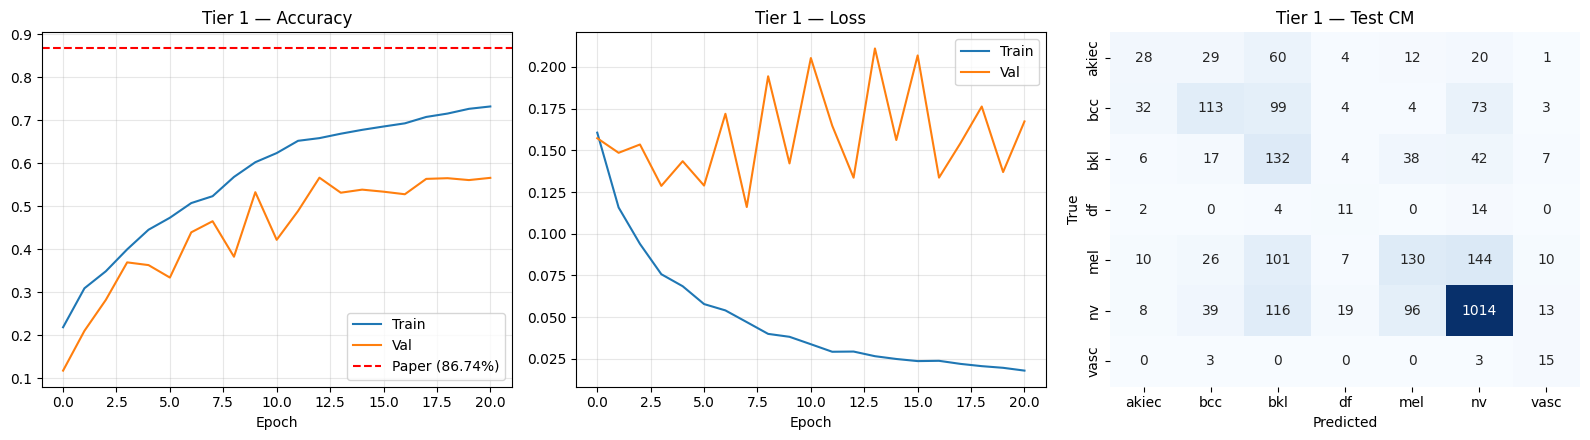


✓ Tier 1 done in 9.3 min
  Test acc: 57.42% (paper: 86.74%)

######################################################################
# TIER 2 — FINAL (best Optuna params)
######################################################################
  Params: {'learning_rate': 8.340431367949276e-05, 'dropout': 0.443073037065547, 'dense1_units': 2048, 'dense2_units': 256, 'rotation_max': 10, 'zoom_range': 0.16401404987609786, 'focal_gamma': 1.7713090263819145}
  Train samples: 10,996 | Steps/epoch: 342
  Total: 9,078,359 | Trainable: 9,013,143
Epoch 1/30
342/342 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.2155 - loss: 0.1508
Epoch 1: val_accuracy improved from None to 0.29774, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier2/D_final/best.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier2/D_final/best.keras
342/342 ━━━━━━━━━━━━━━━━━━━━ 116s 105ms/step - accuracy: 0.2518 - loss: 0.1448 - val_accuracy: 0.2977 - val_loss: 0.1071 - learning_rate: 8.3404e-05
Epoch 2/30
342/342 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.2991 - loss: 0.1154
Epoch 2: val_accuracy improved from 0.29774 to 0.31163, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier2/D_final/best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier2/D_final/best.keras
342/342 ━━━━━━━━━━━━━━━━━━━━ 24s 72ms/step - accuracy: 0.3179 - loss: 0.1159 - val_accuracy: 0.3116 - val_loss: 0.0984 - learning_rate: 8.3404e-05
Epoch 3/30
342/342 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.3482 - loss: 0.0964
Epoch 3: val_accuracy improved from 0.31163 to 0.50218, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier2

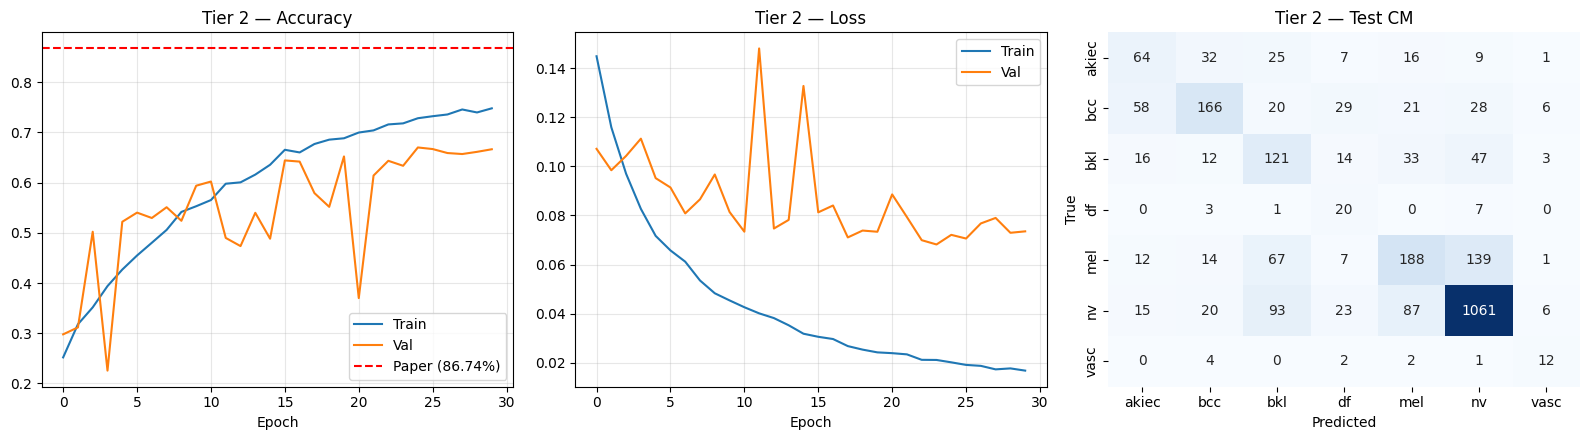


✓ Tier 2 done in 13.8 min
  Test acc: 64.94% (paper: 86.74%)

######################################################################
# TIER 3 — FINAL (best Optuna params)
######################################################################
  Params: {'learning_rate': 8.340431367949276e-05, 'dropout': 0.443073037065547, 'dense1_units': 2048, 'dense2_units': 256, 'rotation_max': 10, 'zoom_range': 0.16401404987609786, 'focal_gamma': 1.7713090263819145}
  Train samples: 14,061 | Steps/epoch: 438
  Total: 9,078,359 | Trainable: 9,013,143
Epoch 1/30
437/438 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.2259 - loss: 0.1350
Epoch 1: val_accuracy improved from None to 0.30488, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier3/D_final/best.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier3/D_final/best.keras
438/438 ━━━━━━━━━━━━━━━━━━━━ 119s 93ms/step - accuracy: 0.2629 - loss: 0.1311 - val_accuracy: 0.3049 - val_loss: 0.0872 - learning_rate: 8.3404e-05
Epoch 2/30
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.2970 - loss: 0.1071
Epoch 2: val_accuracy did not improve from 0.30488
438/438 ━━━━━━━━━━━━━━━━━━━━ 28s 65ms/step - accuracy: 0.3157 - loss: 0.1043 - val_accuracy: 0.2815 - val_loss: 0.0850 - learning_rate: 8.3404e-05
Epoch 3/30
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.3472 - loss: 0.0826
Epoch 3: val_accuracy improved from 0.30488 to 0.42477, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier3/D_final/best.keras

Epoch 3: finished saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier3/D_final/best.keras
438/438 ━━━━━━━━━━━━━━━━━━━━ 30s 68ms/step - accuracy: 0.3643 - loss: 0.0858 - val_acc

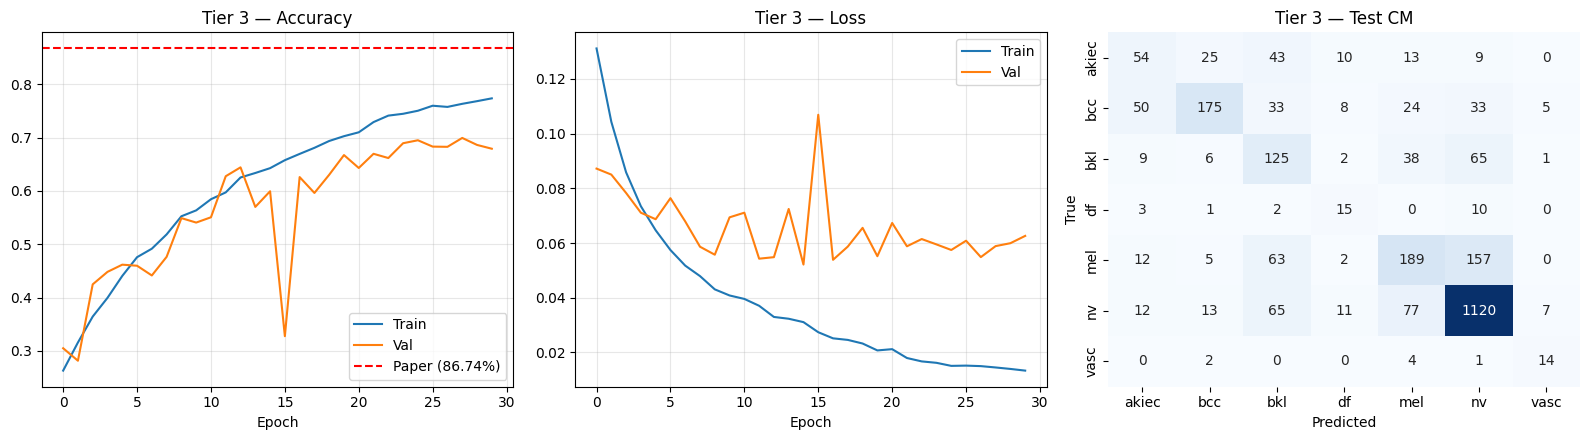


✓ Tier 3 done in 16.4 min
  Test acc: 67.33% (paper: 86.74%)

######################################################################
# TIER 4 — FINAL (best Optuna params)
######################################################################
  Params: {'learning_rate': 8.340431367949276e-05, 'dropout': 0.443073037065547, 'dense1_units': 2048, 'dense2_units': 256, 'rotation_max': 10, 'zoom_range': 0.16401404987609786, 'focal_gamma': 1.7713090263819145}
  Train samples: 17,300 | Steps/epoch: 539
  Total: 9,078,359 | Trainable: 9,013,143
Epoch 1/30
539/539 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.2458 - loss: 0.1285
Epoch 1: val_accuracy improved from None to 0.08615, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier4/D_final/best.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier4/D_final/best.keras
539/539 ━━━━━━━━━━━━━━━━━━━━ 125s 91ms/step - accuracy: 0.2840 - loss: 0.1239 - val_accuracy: 0.0861 - val_loss: 0.1198 - learning_rate: 8.3404e-05
Epoch 2/30
539/539 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.3211 - loss: 0.0918
Epoch 2: val_accuracy improved from 0.08615 to 0.24653, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier4/D_final/best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier4/D_final/best.keras
539/539 ━━━━━━━━━━━━━━━━━━━━ 36s 66ms/step - accuracy: 0.3439 - loss: 0.0935 - val_accuracy: 0.2465 - val_loss: 0.0860 - learning_rate: 8.3404e-05
Epoch 3/30
539/539 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.3566 - loss: 0.0796
Epoch 3: val_accuracy improved from 0.24653 to 0.40611, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier4/

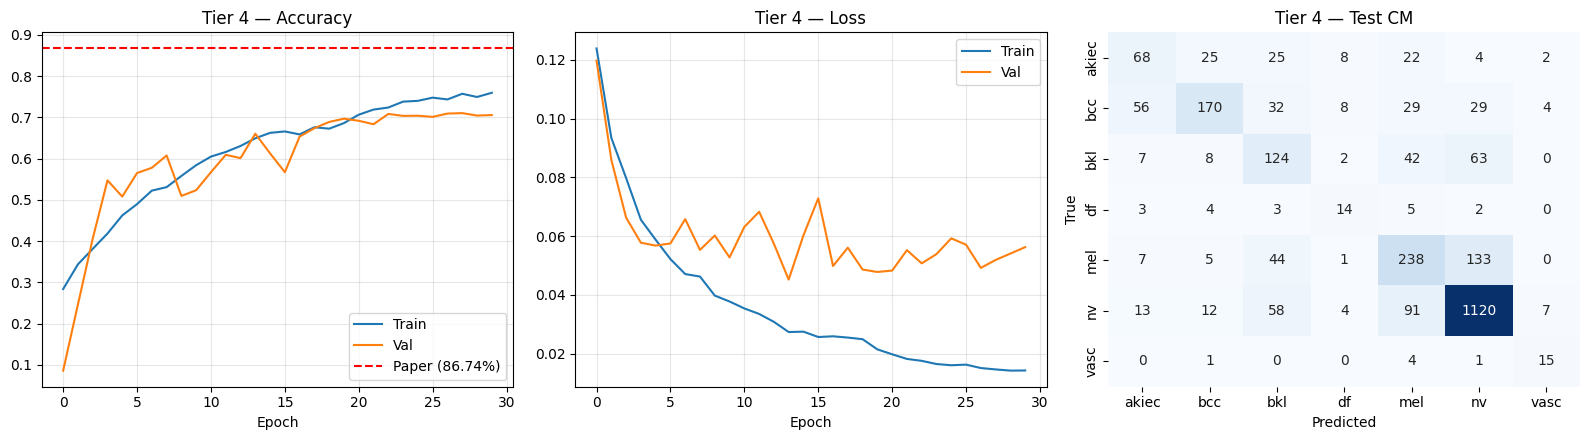


✓ Tier 4 done in 19.5 min
  Test acc: 69.60% (paper: 86.74%)

######################################################################
# TIER 5 — FINAL (best Optuna params)
######################################################################
  Params: {'learning_rate': 8.340431367949276e-05, 'dropout': 0.443073037065547, 'dense1_units': 2048, 'dense2_units': 256, 'rotation_max': 10, 'zoom_range': 0.16401404987609786, 'focal_gamma': 1.7713090263819145}
  Train samples: 20,299 | Steps/epoch: 633
  Total: 9,078,359 | Trainable: 9,013,143
Epoch 1/30
632/633 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.2355 - loss: 0.1183
Epoch 1: val_accuracy improved from None to 0.37237, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier5/D_final/best.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier5/D_final/best.keras
633/633 ━━━━━━━━━━━━━━━━━━━━ 128s 82ms/step - accuracy: 0.2776 - loss: 0.1171 - val_accuracy: 0.3724 - val_loss: 0.0669 - learning_rate: 8.3404e-05
Epoch 2/30
633/633 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.3190 - loss: 0.0856
Epoch 2: val_accuracy improved from 0.37237 to 0.42636, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier5/D_final/best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier5/D_final/best.keras
633/633 ━━━━━━━━━━━━━━━━━━━━ 41s 65ms/step - accuracy: 0.3538 - loss: 0.0853 - val_accuracy: 0.4264 - val_loss: 0.0840 - learning_rate: 8.3404e-05
Epoch 3/30
633/633 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.3740 - loss: 0.0668
Epoch 3: val_accuracy did not improve from 0.42636
633/633 ━━━━━━━━━━━━━━━━━━━━ 42s 66ms/step - accuracy: 0.4007 - loss: 0.0703 - val_acc

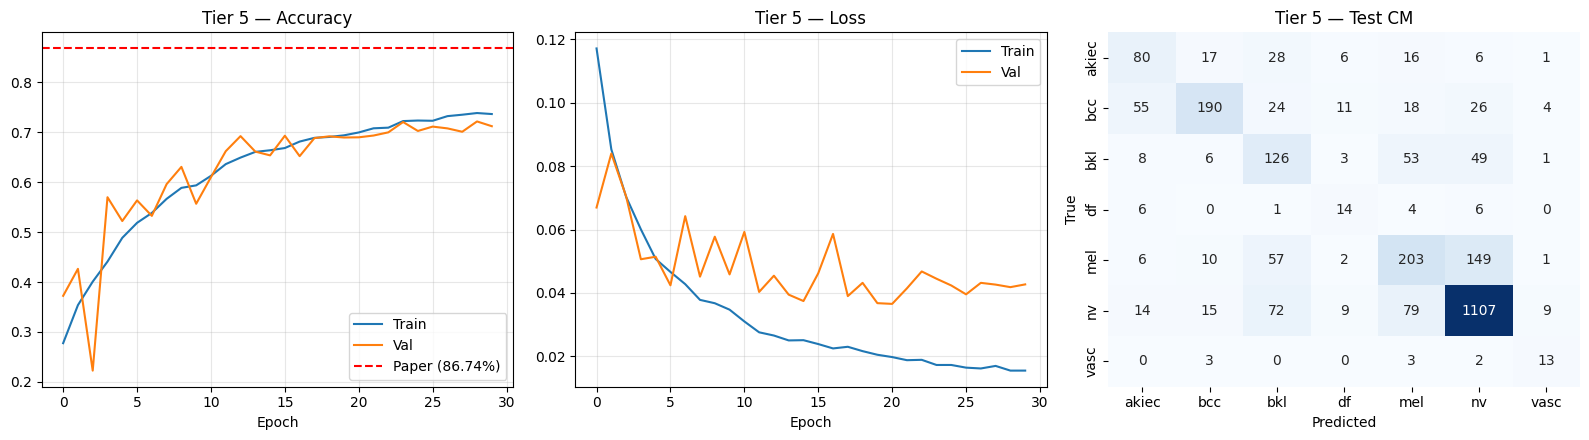


✓ Tier 5 done in 23.3 min
  Test acc: 68.96% (paper: 86.74%)

ALL TIERS FINAL EVAL COMPLETE


In [ ]:
# ─── Run all tiers ───
all_final_results = {}
for tier in [1, 2, 3, 4, 5]:
    res = train_tier_final(tier)
    if res is not None:
        all_final_results[tier] = res

print('\n' + '='*70)
print('ALL TIERS FINAL EVAL COMPLETE')
print('='*70)


## 7. Summary table


In [ ]:
rows = []
for tier, res in sorted(all_final_results.items()):
    row = {
        'tier': tier,
        'epochs': res['epochs_run'],
        'overall_acc': res['overall']['accuracy'] * 100,
        'overall_macro_f1': res['overall']['macro_f1'],
        'overall_weighted_f1': res['overall']['weighted_f1'],
        'overall_auc': res['overall']['auc'],
    }
    for src in ['HAM10000', 'BCN_20000', 'MSK']:
        m = res['per_source'].get(src, {'n_samples': 0})
        if m['n_samples'] > 0:
            row[f'{src}_acc'] = m['accuracy']
            row[f'{src}_f1'] = m['macro_f1']
        else:
            row[f'{src}_acc'] = None
            row[f'{src}_f1'] = None
    row['time_min'] = res['time_minutes']
    rows.append(row)

summary_df = pd.DataFrame(rows)
print(summary_df.to_string(index=False, float_format=lambda x: f'{x:.3f}' if x is not None else 'N/A'))

summary_dir = EXPERIMENTS_DIR / 'summary'
summary_dir.mkdir(parents=True, exist_ok=True)
summary_df.to_csv(summary_dir / 'final_summary.csv', index=False)
print(f'\nSaved: {summary_dir / "final_summary.csv"}')


 tier  epochs  overall_acc  overall_macro_f1  overall_weighted_f1  overall_auc  HAM10000_acc  HAM10000_f1  BCN_20000_acc  BCN_20000_f1  MSK_acc  MSK_f1  time_min
    1      21       57.421             0.405                0.574        0.811         0.744        0.577          0.442         0.309    0.448   0.213     9.306
    2      30       64.942             0.497                0.655        0.880         0.781        0.572          0.544         0.393    0.529   0.284    13.785
    3      30       67.330             0.530                0.671        0.888         0.789        0.603          0.571         0.408    0.586   0.418    16.450
    4      30       69.598             0.563                0.695        0.899         0.813        0.680          0.591         0.426    0.586   0.428    19.493
    5      30       68.961             0.550                0.691        0.893         0.806        0.611          0.600         0.439    0.563   0.321    23.289

Saved: /content/drive/MyDri